Introduction

The first step in a machine learning project is understanding the dataset. In this notebook, the menstrual health dataset is explored to understand its structure, features, data types, and statistical properties.

Exploratory Data Analysis (EDA) is performed to identify missing values, duplicate records, unusual values, and relationships between different features. Visualisations are also used to understand the distribution of the data and identify possible patterns.

This step helps determine whether the dataset is suitable for further preprocessing and machine learning analysis

In [1]:
#Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
#Load dataset

df = pd.read_csv("../Dataset/period - Copy.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Information:")
print(df.info())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (162, 13)

First 5 Records:


,number_of_peak,Age,Length_of_cycle,Estimated_day_of_ovulution,Length_of_Leutal_Phase,Length_of_menses,Unusual_Bleeding,Height,Weight,Income,BMI,Mean_of_length_of_cycle,Menses_score
0,3,18,27,14,9,5,no,5 6,76.0,0,26.3,30,4.0
1,4,18,25,17,10,6,yes,5 6,76.0,0,26.3,30,5.0
2,2,19,30,17,13,4,no,5 3,56.0,0,21.9,30,2.0
3,3,19,28,16,14,6,no,5 1,61.0,0,25.4,30,3.0
4,2,19,35,18,15,5,no,5'3,55.0,0,21.5,35,5.0



Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 162 entries, 0 to 161
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   number_of_peak              162 non-null    int64  
 1   Age                         162 non-null    int64  
 2   Length_of_cycle             162 non-null    int64  
 3   Estimated_day_of_ovulution  162 non-null    int64  
 4   Length_of_Leutal_Phase      162 non-null    int64  
 5   Length_of_menses            162 non-null    int64  
 6   Unusual_Bleeding            162 non-null    str    
 7   Height                      162 non-null    str    
 8   Weight                      162 non-null    float64
 9   Income                      162 non-null    int64  
 10  BMI                         162 non-null    float64
 11  Mean_of_length_of_cycle     162 non-null    int64  
 12  Menses_score                162 non-null    float64
dtypes: float64(3), int64(8), 

,number_of_peak,Age,Length_of_cycle,Estimated_day_of_ovulution,Length_of_Leutal_Phase,Length_of_menses,Weight,Income,BMI,Mean_of_length_of_cycle,Menses_score
count,162.000000,162.000000,162.000000,162.000000,162.000000,162.000000,162.000000,162.0,162.000000,162.000000,162.000000
mean,2.518519,19.333333,29.283951,15.135802,12.753086,5.061728,56.696296,0.0,21.738889,29.320988,3.372840
std,0.706863,1.453204,4.191783,2.352496,3.270538,1.025703,9.471440,0.0,2.975396,5.319196,1.183112
min,1.000000,14.000000,22.000000,7.000000,7.000000,1.000000,40.000000,0.0,16.200000,13.000000,1.000000
25%,2.000000,19.000000,27.000000,14.000000,10.000000,5.000000,51.000000,0.0,20.400000,27.000000,3.000000
50%,2.000000,19.000000,28.000000,15.000000,13.000000,5.000000,55.000000,0.0,21.600000,30.000000,3.000000
75%,3.000000,20.000000,30.000000,16.000000,14.000000,6.000000,60.000000,0.0,22.500000,30.000000,4.000000
max,5.000000,25.000000,40.000000,22.000000,30.000000,8.000000,85.000000,0.0,32.900000,46.000000,5.000000


In [3]:
#Removing duplicate records

print("Before removing duplicates:", df.shape)

df = df.drop_duplicates()

print("After removing duplicates:", df.shape)

Before removing duplicates: (162, 13)
After removing duplicates: (81, 13)


In [4]:
#Cleaning categorical features

df["Unusual_Bleeding"] = (
    df["Unusual_Bleeding"]
    .str.strip()
    .str.lower()
)

print(df["Unusual_Bleeding"].value_counts())

Unusual_Bleeding
no     70
yes    11
Name: count, dtype: int64


In [5]:
#Removing unnecessary features

df = df.drop(columns=["Income", "Height"])

print(df.head())

print("Final Shape:", df.shape)

   number_of_peak  Age  Length_of_cycle  Estimated_day_of_ovulution  \
0               3   18               27                          14   
1               4   18               25                          17   
2               2   19               30                          17   
3               3   19               28                          16   
4               2   19               35                          18   

   Length_of_Leutal_Phase  Length_of_menses Unusual_Bleeding  Weight   BMI  \
0                       9                 5               no    76.0  26.3   
1                      10                 6              yes    76.0  26.3   
2                      13                 4               no    56.0  21.9   
3                      14                 6               no    61.0  25.4   
4                      15                 5               no    55.0  21.5   

   Mean_of_length_of_cycle  Menses_score  
0                       30           4.0  
1                 

In [6]:
df.to_csv("menstrual_health_cleaned.csv", index=False)

print("Dataset saved successfully!")



Dataset saved successfully!


In [7]:
import os

print(os.getcwd())
print(os.listdir())

c:\Users\Muhunthan\Desktop\AI&ML codes class\project\Menstrual_Health_ML_Project\Notebooks
['01_Data_Exploration.ipynb', '02_Feature_Selection.ipynb', '03_Data_Preprocessing.ipynb', '04_Model_Training.ipynb', '05_Model_Evaluation.ipynb', '06_Cross_Validation.ipynb', '07_SHAP_Explainability.ipynb', '08_Final_Visualisation_and_Reporting.ipynb', 'menstrual_health_cleaned.csv']


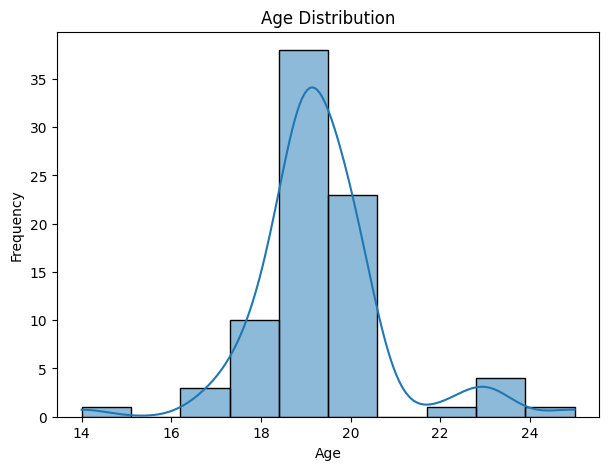

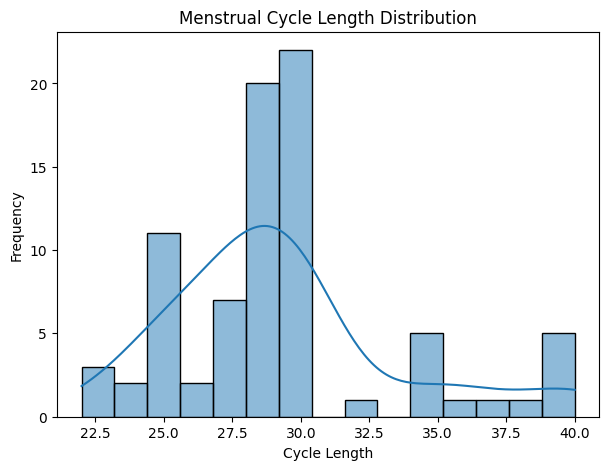

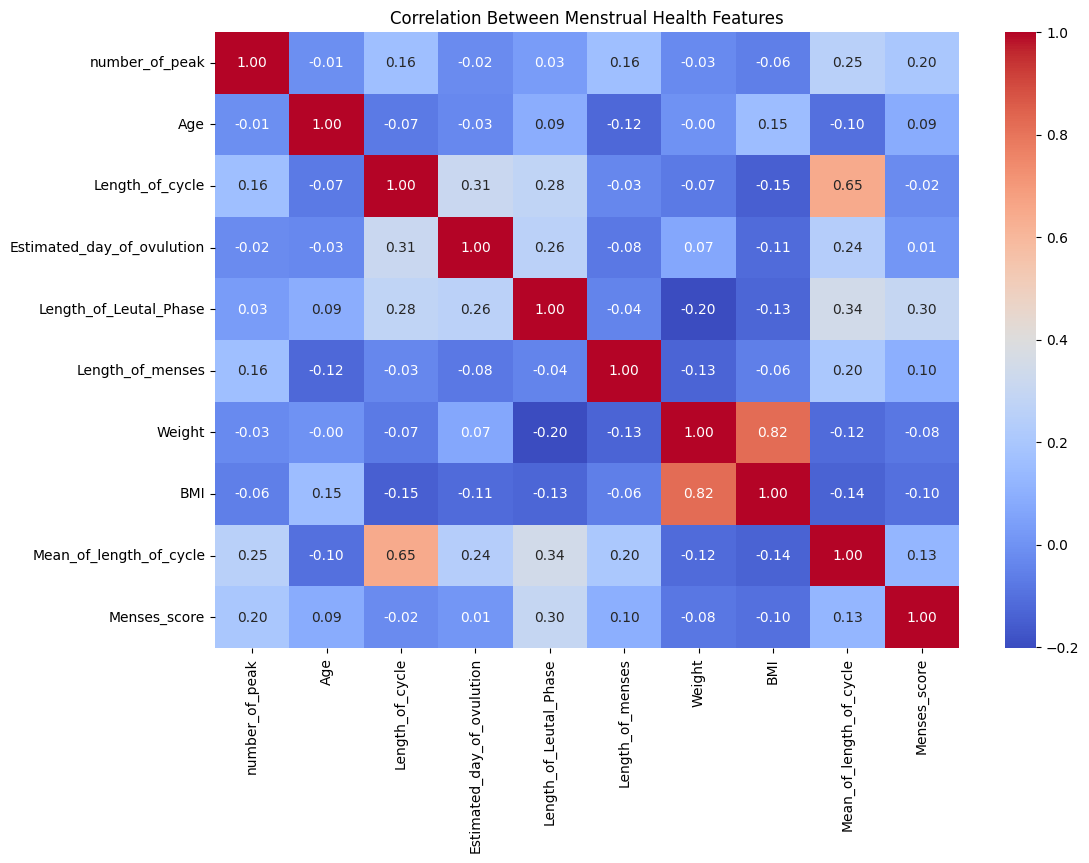

In [8]:
#Visualizing the data
#1.Age distribution
plt.figure(figsize=(7,5))

sns.histplot(df["Age"], bins=10, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

#2.Menstrual cycle distribution

plt.figure(figsize=(7,5))

sns.histplot(df["Length_of_cycle"], bins=15, kde=True)

plt.title("Menstrual Cycle Length Distribution")
plt.xlabel("Cycle Length")
plt.ylabel("Frequency")

plt.show()

#3.Correlation heatmap

plt.figure(figsize=(12,8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Menstrual Health Features")

plt.show()


Conclusion

In this notebook, the menstrual health dataset was successfully explored. The dataset structure, feature types, statistical summaries, and relationships between variables were examined.

Duplicate records and other data quality issues were identified. The exploratory analysis provided an initial understanding of the dataset and helped prepare it for the next stages of the machine learning workflow.